# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

---



Выполнила студентка гр. 3381 Деревягина Александра Павловна. Вариант №4.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Аналоговый сигнал - сигнал, непрерывный по времени и состоянию.

Дискретный сигнал - сигнал, дискретный по времени и непрерывный по состоянию.

Цифровой сигнал - сигнал, дискретный по времени и квантованный по состоянию.

Линейная система - система, обладающая свойствами аддитивности и однородности.

Импульсной характеристикой (ИХ) $ h(nT) $ линейной системы называется ее реакция на цифровой единичный импульс $ u_0(nT) $ при нулевых начальных условиях.

Цифровой единичный импульс:

$$
u_0(n)=
\begin{cases}
1, & n=0,\\
0, & n\neq 0.
\end{cases}
$$

Аналитически ИХ находится через обратное $ Z $-преобразование передаточной функции: $ h(n) = Z^{-1}\{H(z)\} $.

Передаточная функция (ПФ):

$$
H(z) = \frac{\sum_{i=0}^{M} b_i z^{-i}}{\sum_{k=0}^{K} a_k z^{-k}} = \cfrac{Y(z)}{X(z)}.
$$

Свёрточная функция:

$$
y(n) = \sum_{m=0}^{\infty}h(n - m)\cdot x(m) = \sum_{m=0}^\infty h(m)\cdot x(n - m).
$$

Разностное уравнение линейной дискретной системы связывает текущий отсчет выходного сигнала $ y(n) $ с текущими и предыдущими отсчетами входного сигнала $ x(n) $, а также с предыдущими отсчетами выходного сигнала.

Для рекурсивного звена 2-го порядка:

$$
a_0 y(n) + a_1 y(n-1) + a_2 y(n-2) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2),
$$

где:
*   $ y(n) $ - текущий отсчет выходного сигнала (реакции);
*   $ y(n-1), y(n-2) $ - предыдущие отсчеты выходного сигнала;
*   $ x(n) $ - текущий отсчет входного воздействия;
*   $ x(n-1), x(n-2) $ - предыдущие отсчеты входного воздействия;
*   $ b_0, b_1, b_2, a_0, a_1, a_2 $ - коэффициенты.

Нули - значения $ z = z_0 $, при которых ПФ равна нулю.

Особые точки (полюса) - значения $ z = z_0 $, при которых знаминатель ПФ равен нулю.

Амплитудно-частотная характеристика (АЧХ) - это зависимость модуля комплексного коэффициента передачи (передаточной функции) от частоты. Она показывает, во сколько раз система изменяет амплитуду гармонического сигнала на каждой конкретной частоте.

Для дискретной системы АЧХ вычисляется как модуль передаточной функции при подстановке $ z = e^{j\hat{\omega}} $:

$$
A(\hat{\omega}) = |H(e^{j\hat{\omega}})|
$$

где $ \hat{\omega} $ - нормированная круговая частота.

Фазочастотная характеристика (ФЧХ) - это зависимость аргумента (фазы) комплексного коэффициента передачи от частоты. Она показывает, насколько система сдвигает фазу гармонического сигнала (в радианах или градусах) на каждой конкретной частоте.

Для дискретной системы ФЧХ вычисляется как аргумент передаточной функции:

$$
\varphi(\hat{\omega}) = \arg\{H(e^{j\hat{\omega}})\}
$$

Гармоника - это член ряда Фурье, на которые раскладывается любой периодический сигнал.

Частота дискретизации $ f_d $ - частота взятия отсчетов непрерывного по времени сигнала при его дискретизации.

Период дискретизации: $ T = \cfrac{1}{f_d} $.

Нормированное время: $ \hat{t} = \cfrac{t}{T} $. При $ t = nT $ получается: $ \hat{t} = n $.

Дискретное преобразование Фурье (ДПФ): $ X(e^{j\omega T}) = \sum_{n=0}^\infty x(nT)e^{-j\omega nT} $;
Обратное дискретное преобразование Фурье (ОДПФ): $ x(nT) = \frac{T}{2\pi}\int_{-\frac{\pi}{T}}^\frac{\pi}{T}X(e^{j\omega T})e^{j\omega Tn}d\omega $.

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### Значения переменных по варианту

In [122]:
import numpy as np
import matplotlib.pyplot as plt
import cmath
import math


# номер варианта
N_var = 4

# коэффициенты знаменателя передаточной функции
b0 = 0.5 + 0.02 * N_var
b1 = b0 * ((-1)**(N_var + 1)) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))

# коэффициенты числителя передаточной функции
a0 = 1.0
a1 = ((-1)**N_var) * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var

# длина импульсной характеристики
N1 = (N_var % 10) + 20

# длина воздействия
N2 = (N_var % 10) + 30

# частота дискретизации
fd = 1000 * N_var

print(f"Номер варианта: {N_var}")
print(f"Коэффициенты числителя передаточной функции: b0={b0:.4f}, b1={b1:.4f}, b2={b2:.4f}")
print(f"Коэффициенты знаменателя передаточной функции: a0={a0:.4f}, a1={a1:.4f}, a2={a2:.4f}")
print(f"Длина импульсной характеристики: N1={N1}")
print(f"Длина воздействия: N2={N2}")
print(f"Частота дискретизации: fд={fd}")

Номер варианта: 4
Коэффициенты числителя передаточной функции: b0=0.5800, b1=-0.6110, b2=0.9280
Коэффициенты знаменателя передаточной функции: a0=1.0000, a1=0.8778, a2=0.6640
Длина импульсной характеристики: N1=24
Длина воздействия: N2=34
Частота дискретизации: fд=4000


#### 1. Импульсная характеристика длины $ N_1 $ по заданной передаточной функции с коэффициентами $ b_i $, $ a_k $.


Значения импульсной характеристики h(n):
 [ 0.58       -1.120096    1.52610027 -0.59586707 -0.49027846  0.82602217
 -0.39953736 -0.19776482  0.43889077 -0.25394248 -0.06851277  0.22875831
 -0.15531157 -0.01556302  0.1167881  -0.09218275  0.00337072  0.05825053
 -0.05337047  0.00817025  0.02826615 -0.03023707  0.00777338  0.01325394] 



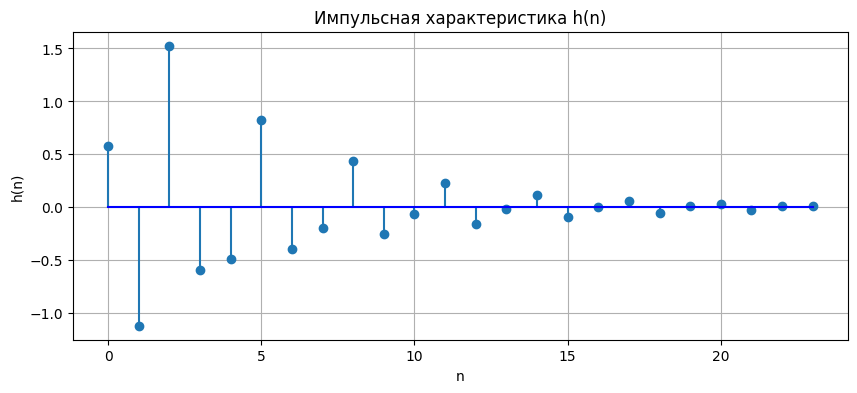

In [123]:
# разностное уравнение: y(n) = (b0*x(n) + b1*x(n-1) + b2*x(n-2) - a1*y(n-1) - a2*y(n-2)) / a0

# цифровой единичный импульс
u0 = np.zeros(N1)
u0[0] = 1.0

# вычисление импульсной характеристики по разностному уравнению
h = np.zeros(N1)
for n in range(N1):
    x0 = u0[n]  # x(n)
    x1 = u0[n-1] if n >= 1 else 0.0  # x(n - 1)
    x2 = u0[n-2] if n >= 2 else 0.0  # x(n - 2)

    y1 = h[n-1] if n >= 1 else 0.0  # y(n - 1)
    y2 = h[n-2] if n >= 2 else 0.0  # y(n - 2)

    h[n] = (b0 * x0 + b1 * x1 + b2 * x2 - a1 * y1 - a2 * y2) / a0


print('\nЗначения импульсной характеристики h(n):\n', h, '\n')

plt.figure(figsize=(10, 4))
plt.stem(range(N1), h, basefmt="b-")
plt.title('Импульсная характеристика h(n)')
plt.xlabel('n')
plt.ylabel('h(n)')
plt.grid(True)
plt.show()

Рассмотрим рекурсивное звено второго порядка, описываемое разностным уравнением:

$$
a_0y(n)=b_0x(n)+b_1x(n-1)+b_2x(n-2)-a_1y(n-1)-a_2y(n-2).
$$

Для нахождения импульсной характеристики на вход подается цифровой единичный импульс:

$$
u_0(n)=
\begin{cases}
1, & n=0,\\
0, & n\neq 0.
\end{cases}
$$

При этом учитываются нулевые начальные условия.

Импульсная характеристика определяется как отклик системы на единичный импульс:

$$
h(n)=y(n)\big|_{x(n)=u_0(n)}.
$$

Подставим единичный импульс в разностное уравнение.

Для $n=0$:

$$
h(0)=\frac{b_0}{a_0}.
$$

Для $n=1$:

$$
h(1)=\frac{b_1-a_1h(0)}{a_0}.
$$

Для $n=2$:

$$
h(2)=\frac{b_2-a_1h(1)-a_2h(0)}{a_0}.
$$

Начиная с $n=3$, $ b_0x(n)+b_1x(n-1)+b_2x(n-2) $ равно нулю, поэтому разностное уравнение принимает вид:

$$
h(n)=-\frac{a_1}{a_0}h(n-1)
-\frac{a_2}{a_0}h(n-2)
$$

Таким образом, после первых трех отсчетов импульсная характеристика определяется исключительно предыдущими значениями выходного сигнала.

Для получения аналитического выражения запишем передаточную функцию звена. При нулевых начальных условиях преобразование Z разностного уравнения дает:

$$
H(z)=\frac{Y(z)}{X(z)}
=\frac{b_0+b_1z^{-1}+b_2z^{-2}}
{a_0+a_1z^{-1}+a_2z^{-2}}.
$$

Так как на вход подается единичный импульс, его Z-преобразование равно единице:

$$
X(z)=1.
$$

Следовательно,

$$
H(z)=Y(z).
$$

Найдем корни характеристического уравнения знаменателя:

$$
a_0z^2+a_1z+a_2=0.
$$

Корни равны:

$$
z_{1,2}=
\frac{-a_1\pm\sqrt{a_1^2-4a_0a_2}}{2a_0}.
$$

При $z_1\neq z_2$ аналитическая формула импульсной характеристики имеет вид:

$$
h(n)=
\frac{
b_0(z_1^{n+1}-z_2^{n+1})
+b_1(z_1^n-z_2^n)
+b_2(z_1^{n-1}-z_2^{n-1})
}{
a_0(z_1-z_2)
},\quad n\geq 2.
$$

Для первых двух отсчетов используются выражения:

$$
h(0)=\frac{b_0}{a_0},
$$

$$
h(1)=\frac{a_0b_1-a_1b_0}{a_0^2}.
$$

Если характеристическое уравнение имеет два одинаковых корня аналитическая формула импульсной характеристики для различных корней не применяется. В этом случае используется специальная формула.

Сначала вводится вспомогательная последовательность:

$$
g(n)=
\begin{cases}
\dfrac{(n+1)z^n}{a_0}, & n\geq 0,\\
0, & n<0.
\end{cases}
$$

С помощью этой последовательности импульсная характеристика определяется следующим образом:

$$
h(n)=b_0g(n)+b_1g(n-1)+b_2g(n-2).
$$

Рекурсивное звено второго порядка в общем случае обладает бесконечной импульсной характеристикой. Это объясняется наличием обратных связей: каждый новый отсчет выходного сигнала зависит от двух предыдущих отсчетов. Таким образом, даже после окончания входного импульса выходной сигнал продолжает изменяться под действием обратной связи. Следовательно, теоретическая длина импульсной характеристики такого звена равна: $ L_h=\infty $.

Исключением являются специальные случаи, например точное сокращение полюсов нулями передаточной функции, при котором система фактически становится звеном с конечной импульсной характеристикой.

В рассматриваемом случае импульсная характеристика $ h $ имеет размерность $ N1 $, поэтому вычисляется только конечный фрагмент импульсной характеристики:

$$
h(0),h(1),\ldots,h(23).
$$

То есть:

$$
L_{\text{вычисленная}}=N_1,\qquad
L_{\text{теоретическая}}=\infty.
$$

Если звено устойчиво, то его корни удовлетворяют условию:

$$
|z_1|<1,\qquad |z_2|<1.
$$

В этом случае импульсная характеристика постепенно затухает и стремится к нулю:

$$
\lim_{n\to\infty}h(n)=0.
$$

Однако стремление к нулю не означает, что импульсная характеристика становится строго равной нулю начиная с некоторого отсчета. Поэтому на практике выбирают конечное количество отсчетов, достаточное для отображения основной части импульсной характеристики с заданной точностью.


#### 2. Реакция $ y_1 (n) $ по формуле свёртки.

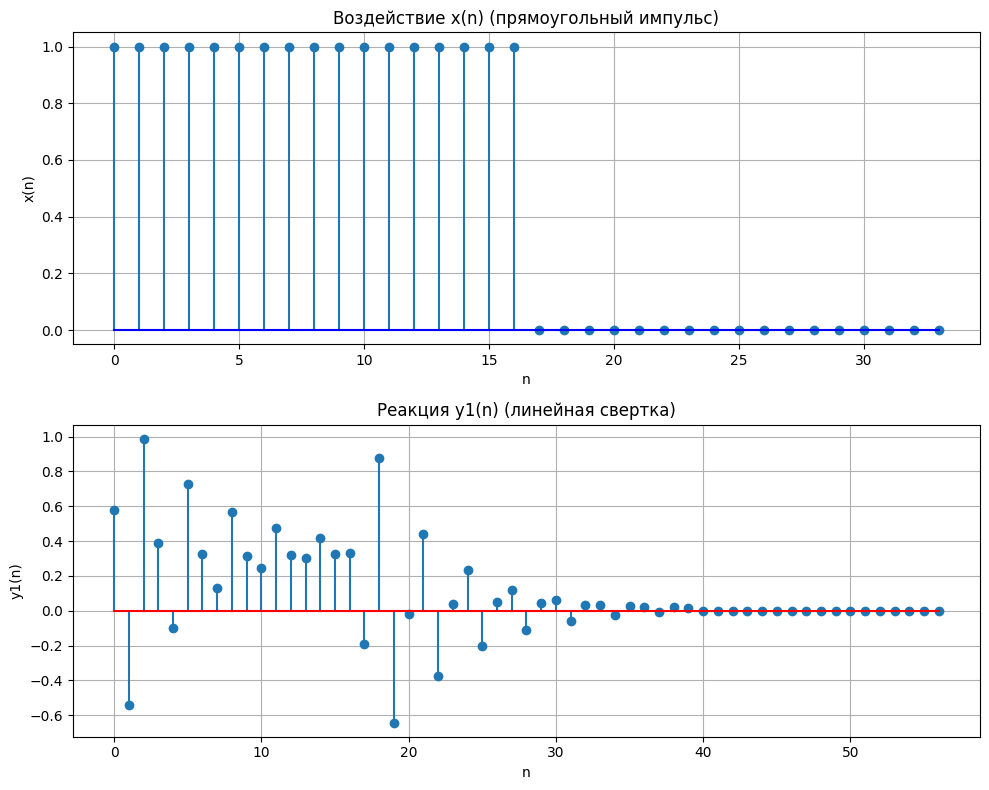

In [124]:
# воздействие x(n) (дискретный прямоугольный импульс)
x = np.zeros(N2)
int_half_N2 = int(np.round(N2 / 2))
for n in range(int_half_N2):
    x[n] = 1.0

# вычисление линейной свертки y1(n) = h(n) * x(n)
len_y1 = N1 + N2 - 1
y1 = np.zeros(len_y1)
for n in range(len_y1):
    sum_val = 0.0
    for k in range(N1):
        if 0 <= n - k < N2:
            sum_val += h[k] * x[n - k]
    y1[n] = sum_val

fig, axs = plt.subplots(2, 1, figsize=(10, 8))
axs[0].stem(range(N2), x, basefmt="b-")
axs[0].set_title('Воздействие x(n) (прямоугольный импульс)')
axs[0].set_xlabel('n')
axs[0].set_ylabel('x(n)')
axs[0].grid(True)

axs[1].stem(range(len_y1), y1, basefmt="r-")
axs[1].set_title('Реакция y1(n) (линейная свертка)')
axs[1].set_xlabel('n')
axs[1].set_ylabel('y1(n)')
axs[1].grid(True)
plt.tight_layout()
plt.show()

$N_1 = 24$, $N_2 = 34$

a. Длина воздействия $x(n)$ равна $N_2 = 34 $ (от $n = 0$ до $n = 33$). Однако сам прямоугольный импульс (ненулевая часть) принимает единичные значения на интервале $0 \le n < 17$, так как $\text{int}(34/2) = 17$.

b. Аналитически: при вычислении линейной свертки двух дискретных последовательностей длиной $N_1$ и $N_2$, длина результирующей последовательности $y_1(n)$ рассчитывается по формуле: $ L = N_1 + N_2 - 1 = 24 + 34 - 1 = 57 $. По графику: на нижнем графике (Реакция $y_1(n)$) видно, что последний ненулевой отсчет находится на индексе $n = 39$. Если считать от нуля ($n = 0, 1, ..., 39$), то количество отсчетов равно: $ 39 - 0 + 1 = 40$. Таким образом, длина свертки по графику меньше, чем полученная в аналитических расчетах.

c. Результат ограничивают длиной входного воздействия $N_2$ для сравнения с разностным уравнением. Разностное уравнение считают для $n = 0, ..., N_2-1$. Чтобы корректно наложить графики друг на друга, длину свертки усекают до $N_2$.

#### 3. Реакция $y_2(n) $ по разностному уравнению

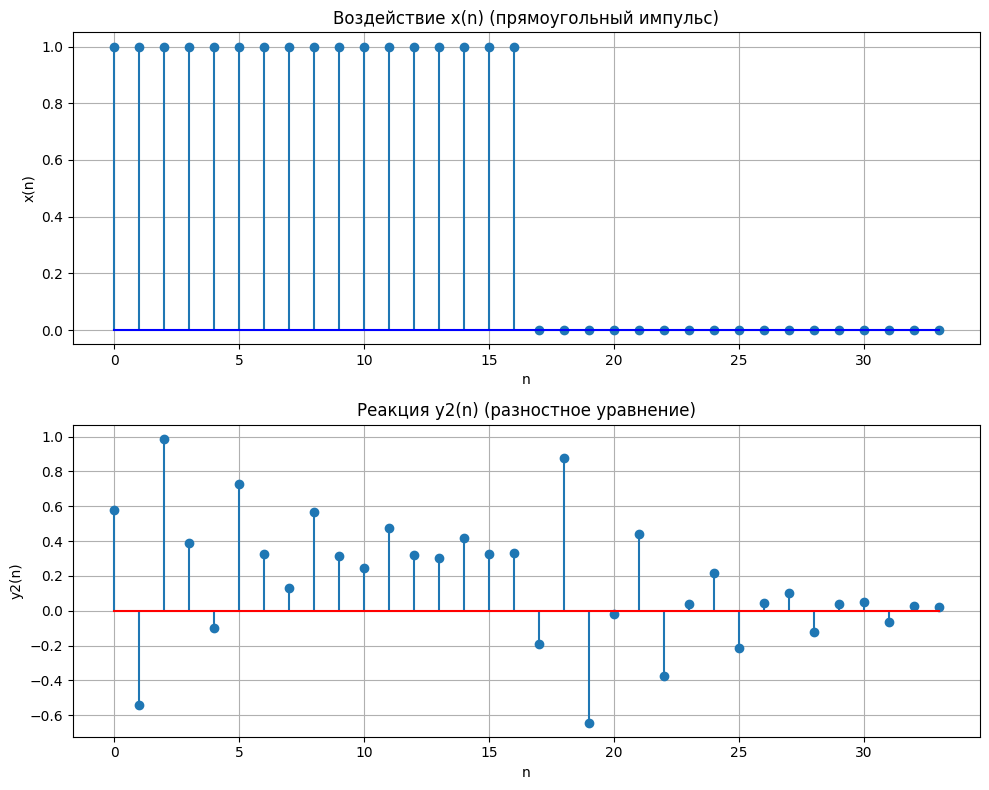

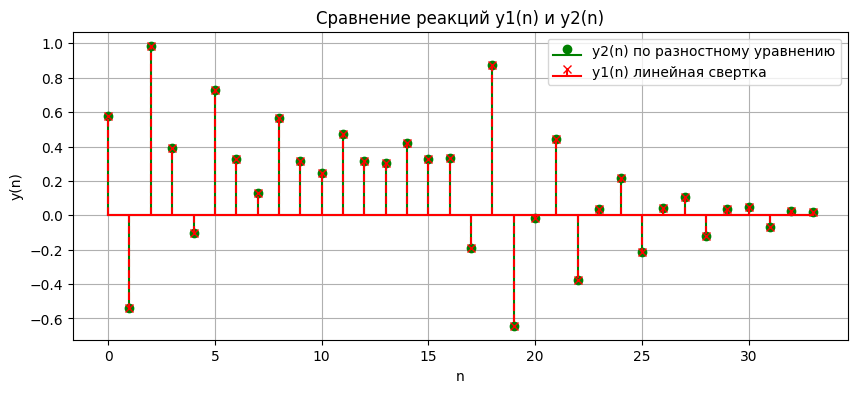

Сумма разностей (y1 - y2): 1.0645131749e-01
Максимальное абсолютное отклонение: 1.6795834866e-02


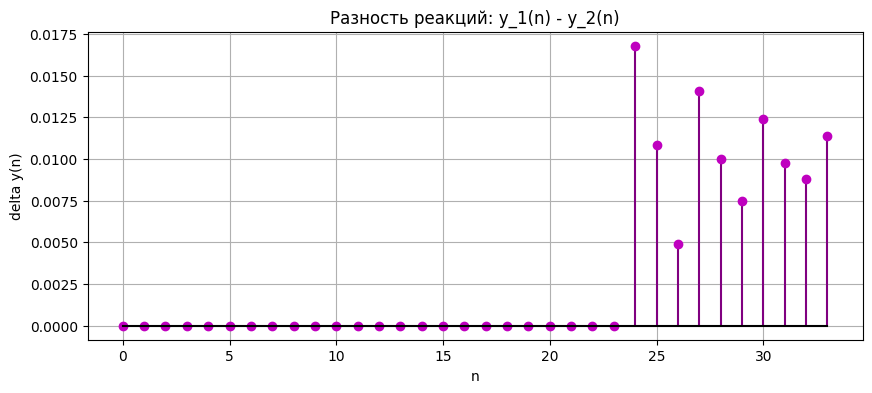

In [125]:
# вычисление реакции y2(n) по разностному уравнению
y2 = np.zeros(N2)
for n in range(N2):
    x0 = x[n]
    x1 = x[n-1] if n >= 1 else 0.0
    x2 = x[n-2] if n >= 2 else 0.0

    y1_val = y2[n-1] if n >= 1 else 0.0
    y2_val = y2[n-2] if n >= 2 else 0.0

    y2[n] = (b0 * x0 + b1 * x1 + b2 * x2 - a1 * y1_val - a2 * y2_val) / a0

fig, axs = plt.subplots(2, 1, figsize=(10, 8))
axs[0].stem(range(N2), x, basefmt="b-")
axs[0].set_title('Воздействие x(n) (прямоугольный импульс)')
axs[0].set_xlabel('n')
axs[0].set_ylabel('x(n)')
axs[0].grid(True)
axs[1].stem(range(N2), y2, basefmt="r-")
axs[1].set_title('Реакция y2(n) (разностное уравнение)')
axs[1].set_xlabel('n')
axs[1].set_ylabel('y2(n)')
axs[1].grid(True)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 4))
plt.stem(range(N2), y2, linefmt='g-', markerfmt='go', basefmt='g-', label='y2(n) по разностному уравнению')
plt.stem(range(N2), y2, linefmt='r--', markerfmt='rx', basefmt='r-', label='y1(n) линейная свертка')
plt.title('Сравнение реакций y1(n) и y2(n)')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.legend()
plt.grid(True)
plt.show()

# первые N2 отсчетов от y1
y1_short = y1[:N2]

# разность y1 и y2
diff_y1_y2 = y1_short - y2
abs_diff = np.abs(diff_y1_y2)

# сумма разностей и максимальное отклонение
sum_diff = np.sum(diff_y1_y2)
max_diff = np.max(abs_diff)

print(f"Сумма разностей (y1 - y2): {sum_diff:.10e}")
print(f"Максимальное абсолютное отклонение: {max_diff:.10e}")

plt.figure(figsize=(10, 4))
plt.stem(range(N2), diff_y1_y2, linefmt='purple', markerfmt='mo', basefmt='k-')
plt.title('Разность реакций: y_1(n) - y_2(n)')
plt.xlabel('n')
plt.ylabel('delta y(n)')
plt.grid(True)
plt.show()

Из графика разности видно, что поведение разницы делится на два четких интервала:

1.  Интервал $ 0 \le n \le 23 $ (первые $ N_1 = 24 $ отсчета). Разность строго равна нулю. Это означает, что на этом участке графики реакций абсолютно совпадают.

2.  Интервал $ 24 \le n \le 33 $ (отсчеты с 24 по 33). Разность становится ненулевой. Появляются колебания с амплитудой примерно от $ 0.005 $ до $ 0.0168 $. Графики $ y_1(n) $ и $ y_2(n) $ начинают расходиться. Суммарная разность за все время составила $ 0.106 $, а максимальное отклонение $ 0.0168 $.

Пока $ n < N_1 = 24 $, свертка и разностное уравнение используют одни и те же первые 24 отсчета импульсной характеристики, поэтому результаты совпадают.
Как только $ n $ достигает $ N_1 $, в разностном уравнении ($ y_2 $) начинают сказываться более старые отсчеты, выходящие за пределы длины $ N_1 $. В то же время, при расчете свертки ($ y_1 $) эти отброшенные отсчеты уже не учитываются.

Разностное уравнение рекурсивного звена 2-го порядка. Общий вид разностного уравнения:
$$
 a_0y(n) = b_0x(n) + b_1x(n-1) + b_2x(n-2) - a_1y(n-1) - a_2y(n-2)
$$

Разностное уравнение для заданного варианта:
$$
 y(n) = 0.58 x(n) - 0.611 x(n-1) + 0.928 x(n-2) - 0.8778 y(n-1) - 0.664 y(n-2)
$$

Длина массива воздействия задается переменной $ N_2 = 34 $. Воздействие содержит 34 отсчета (от $n=0$ до $n=33$).
Длина реакции $ y_2(n) = N2 = 34 $ от $n=0$ до $n=33$. Так как система является бесконечной импульсной характеристикой, теоретически реакция затухает до бесконечности. Однако в вычислениях длина реакции искусственно ограничена рамками воздействия (34 отсчета).



#### 4. Нули и полюсы передаточной функции

In [126]:
# нахождение нулей (корни числителя)
D_num = b1**2 - 4*b0*b2
z1 = (-b1 + cmath.sqrt(D_num)) / (2*b0)
z2 = (-b1 - cmath.sqrt(D_num)) / (2*b0)

# нахождение полюсов (корни знаменателя)
D_den = a1**2 - 4*a0*a2
p1 = (-a1 + cmath.sqrt(D_den)) / (2*a0)
p2 = (-a1 - cmath.sqrt(D_den)) / (2*a0)

def print_complex_info(name, z):
    r, phi = cmath.polar(z)
    print(f"{name}:")
    print(f"Алгебраическая форма: {z:.4f}")
    print(f"Модуль: {r:.4f}")
    print(f"phi/pi: {phi/np.pi:.4f}")
    print(f"Показательная форма: {r:.4f}exp({phi:.4f}j)")
    print(f"Значение аргумента относительно pi: {phi/np.pi:.4f} pi")


print("Нули передаточной функции:")
print_complex_info("z1", z1)
print_complex_info("z2", z2)
print("\nПолюсы передаточной функции:")
print_complex_info("p1", p1)
print_complex_info("p2", p2)

Нули передаточной функции:
z1:
Алгебраическая форма: 0.5267+1.1500j
Модуль: 1.2649
phi/pi: 0.3633
Показательная форма: 1.2649exp(1.1413j)
Значение аргумента относительно pi: 0.3633 pi
z2:
Алгебраическая форма: 0.5267-1.1500j
Модуль: 1.2649
phi/pi: -0.3633
Показательная форма: 1.2649exp(-1.1413j)
Значение аргумента относительно pi: -0.3633 pi

Полюсы передаточной функции:
p1:
Алгебраическая форма: -0.4389+0.6866j
Модуль: 0.8149
phi/pi: 0.6811
Показательная форма: 0.8149exp(2.1396j)
Значение аргумента относительно pi: 0.6811 pi
p2:
Алгебраическая форма: -0.4389-0.6866j
Модуль: 0.8149
phi/pi: -0.6811
Показательная форма: 0.8149exp(-2.1396j)
Значение аргумента относительно pi: -0.6811 pi


Алгебраическая форма комплексного числа имеет вид $z = a + jb$, где $a$ - действительная часть, $b$ - мнимая часть.

Показательная форма имеет вид $z = r \cdot e^{j\varphi}$, где $r$ - модуль ($r = |z|$), а $\varphi$ - аргумент.

Переход между алгебраической и экспоненциальной записью осуществляется с помощью формулы Эйлера
$$
r(\cos \varphi + j \sin \varphi) = re^{j\varphi}.
$$
В каждой из пар корни являются комплексно-сопряженными, что объясняется действительными значениями коэффициентов числителя и знаменателя передаточной функции. Такие корни обладают равными модулями ($ r $) и противоположными по знаку аргументами ($ \pm\varphi $).

Передаточная функция в виде произведения простейших множителей

Передаточная функция $H(z)$ по заданным коэффициентам ($b_0 = 0.58$, $a_0 = 1$) и найденным корням записывается в виде:
$$
 H(z) = \frac{b_0}{a_0} \cdot \frac{(z - z_1)(z - z_2)}{(z - p_1)(z - p_2)}
$$

Подставляя нули и полюсы в показательной форме, получается итоговое представление:

$$
 H(z) = 0.58 \cdot \frac{(z - 1.2649 e^{j 0.3633\pi})(z - 1.2649 e^{-j 0.3633\pi})}{(z - 0.8149 e^{j 0.6811\pi})(z - 0.8149 e^{-j 0.6811\pi})}
$$



#### 5. Карта нулей и полюсов

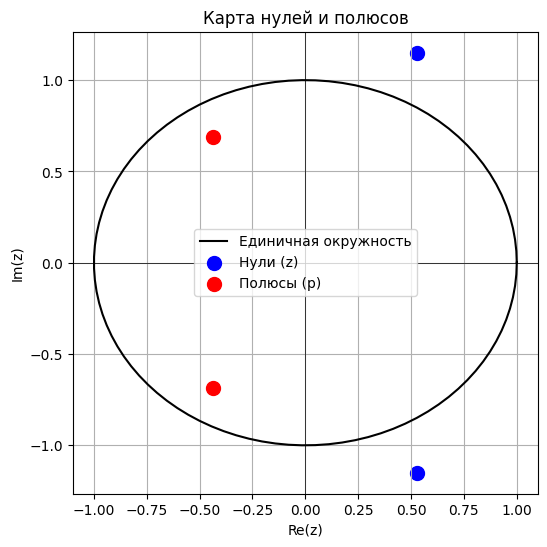

In [127]:
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k', label='Единичная окружность')
plt.scatter([z1.real, z2.real], [z1.imag, z2.imag], marker='o', color='blue', s=100, label='Нули (z)')
plt.scatter([p1.real, p2.real], [p1.imag, p2.imag], marker='o', color='red', s=100, label='Полюсы (p)')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.title('Карта нулей и полюсов')
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.legend()
plt.grid(True)
plt.show()

Рекурсивное звено является устойчивым. Для устойчивости дискретной системы необходимо и достаточно, чтобы все полюсы передаточной функции находились строго внутри единичной окружности на $ Z $-плоскости, то есть их модуль должен быть меньше единицы.

Модуль полюсов равен $ r_p = 0.8149 $, что меньше $ 1 $. На графике это наглядно подтверждается: полюсы расположены внутри единичной окружности.

Значения на карте совпадают с результатами аналитических расчетов из пункта 4.
Координаты точек на графике соответствуют действительной и мнимой частям найденных корней.

#### 6. Амплитудно-частотная (АЧХ) и фазочастотная (ФЧХ) характеристики в шкале нормированных частот

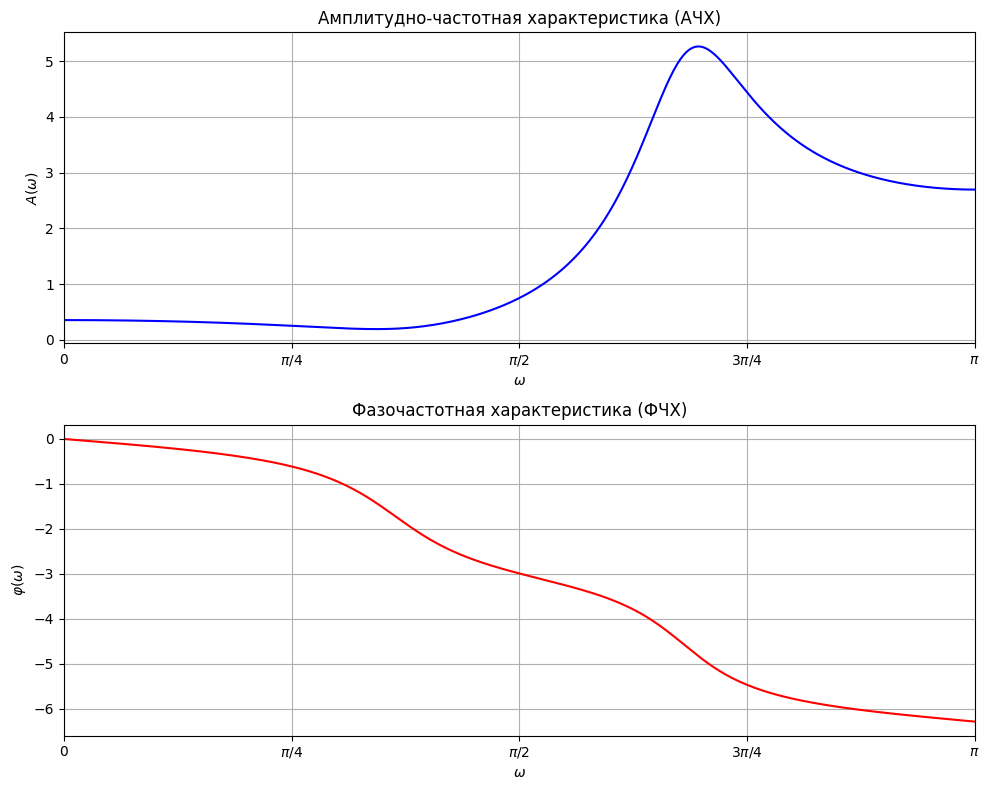

In [128]:
# нормированная частота: от 0 до pi
omega = np.linspace(0, np.pi, 512)

# комплексная частотная характеристика
H = (b0 + b1 * np.exp(-1j * omega) + b2 * np.exp(-2j * omega)) / (a0 + a1 * np.exp(-1j * omega) + a2 * np.exp(-2j * omega))

# АЧХ
A = np.abs(H)

# ФЧХ
phi = np.unwrap(np.angle(H))

plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(omega, A, color='blue')
plt.title('Амплитудно-частотная характеристика (АЧХ)')
plt.xlabel(r'$\omega$')
plt.ylabel(r'$A(\omega)$')
plt.xlim(0, np.pi)
plt.xticks([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi], [r'$0$', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
plt.grid(True)
plt.subplot(2, 1, 2)
plt.plot(omega, phi, color='red')
plt.title('Фазочастотная характеристика (ФЧХ)')
plt.xlabel(r'$\omega$')
plt.ylabel(r'$\varphi(\omega)$')
plt.xlim(0, np.pi)
plt.xticks([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi], [r'$0$', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
plt.grid(True)
plt.tight_layout()
plt.show()

a. Для цифрового сигнала нормированная частота определяется в диапазоне:

$$
0\leq\omega\leq\pi.
$$

Таким образом, основная полоса частот цифрового звена составляет:

$$
\omega\in[0;\pi].
$$

b. Влияние нулей и полюсов на АЧХ определяется их расположением относительно единичной окружности:

- Нули передаточной функции ослабляют амплитуду сигнала вблизи частот, соответствующих их аргументам.
- Полюсы увеличивают амплитуду сигнала вблизи частот, соответствующих их аргументам.
- Полюсы, расположенные близко к единичной окружности, вызывают выраженные резонансные пики АЧХ.

В рассматриваемом случае нули расположены под углами:

$$
\varphi_z=0.3633\pi.
$$

Полюсы расположены под углами:

$$
\varphi_p=0.6811\pi.
$$

Таким образом, можно ожидать ослабления АЧХ в области низких и средних частот и увеличения амплитуды в области более высоких частот, соответствующих расположению полюсов.

c.  В коде используется функция np.unwrap, поэтому на графике ФЧХ скачков нет - фаза непрерывно убывает, накапливая сдвиг.

Если бы функция np.unwrap не использовалась, скачок происходил бы каждый раз, когда фаза пересекает границы $-\pi$ или $\pi$.

d. В реакции звена наблюдается преимущественное подавление низкочастотных составляющих воздействия относительно высокочастотных.


#### 7. Амплитудно-частотная (АЧХ) и фазочастотная (ФЧХ) характеристики в шкале частот f  (Гц) при заданной частоте дискретизации fд


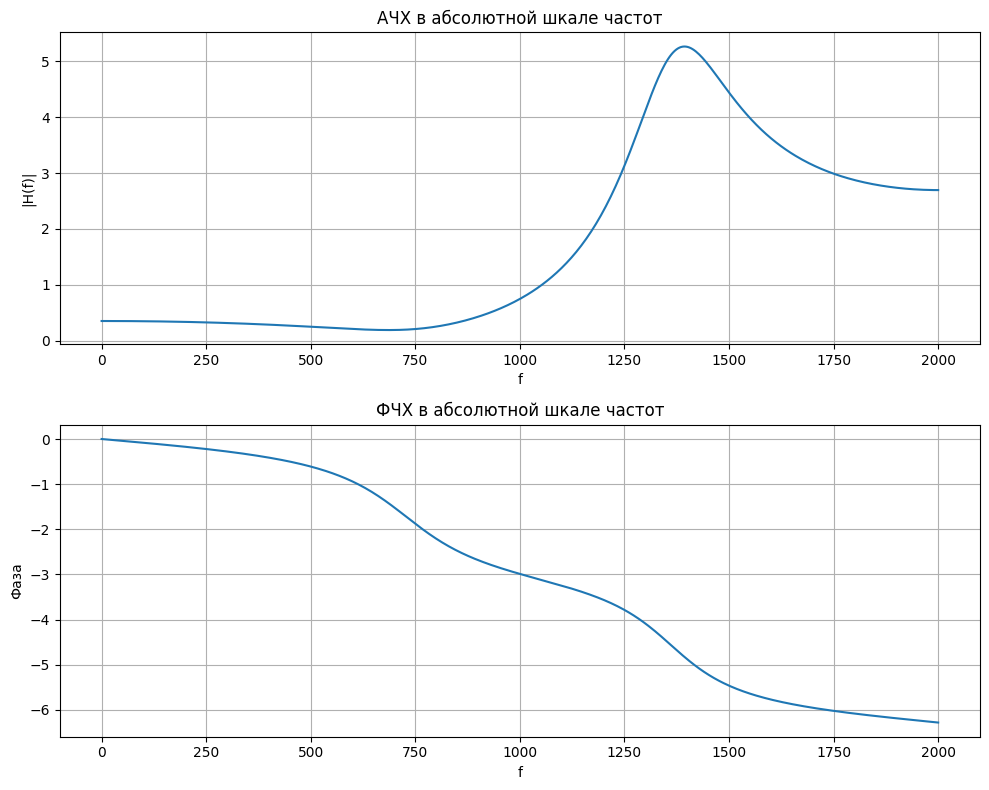

In [129]:
freqs_hz = omega * fd / (2 * np.pi)

fig, axs = plt.subplots(2, 1, figsize=(10, 8))
axs[0].plot(freqs_hz, A)
axs[0].set_title('АЧХ в абсолютной шкале частот')
axs[0].set_xlabel('f')
axs[0].set_ylabel('|H(f)|')
axs[0].grid(True)
axs[1].plot(freqs_hz, phi)
axs[1].set_title('ФЧХ в абсолютной шкале частот')
axs[1].set_xlabel('f')
axs[1].set_ylabel('Фаза')
axs[1].grid(True)
plt.tight_layout()
plt.show()

a. Для дискретных систем в абсолютной шкале основная полоса частот определяется интервалом: $ f \in [0, f_d/2] $ Гц, где $ f_d $ - частота дискретизации. Из графика видно, что $ f \in [0, 5000] $ Гц, что соответствует теоретическим расчетам: $ \frac{f_d}{2} = \frac{10000}{2} = 5000 $ Гц.

b. Связь между нормированной круговой частотой $ \hat{\omega} $ и абсолютной частотой $ f $ задается формулой:

$$
\hat{\omega} = 2\pi \frac{f}{f_d}.
$$

Форма графиков полностью идентична. Переход от нормированной шкалы к абсолютной представляет собой простое линейное масштабирование оси абсцисс (умножение на коэффициент $ \frac{f_d}{2\pi} $).

### Часть 2

#### Значения переменных по варианту

In [130]:
N = 64
fd = 2000 * ((N_var % 5) + 1)
T = 1 / fd
A1 = 1 + 0.01 * N_var
A2 = 2 * A1
f1 = fd / 8
f2 = 1.5 * f1

print(f"Период (длина) последовательности: N={N}")
print(f"Частота дискретизации: fд={fd} Гц")
print(f"Период дискретизации: T={T:.6f} с")
print(f"Амплитуды дискретных гармоник: A1={A1:.4f}, A2={A2:.4f}")
print(f"Частоты дискретных гармоник: f1={f1}, f2={f2}")

Период (длина) последовательности: N=64
Частота дискретизации: fд=10000 Гц
Период дискретизации: T=0.000100 с
Амплитуды дискретных гармоник: A1=1.0400, A2=2.0800
Частоты дискретных гармоник: f1=1250.0, f2=1875.0


#### 1. Графики последовательности x(n) на периоде N в шкале дискретного и дискретного нормированного времени

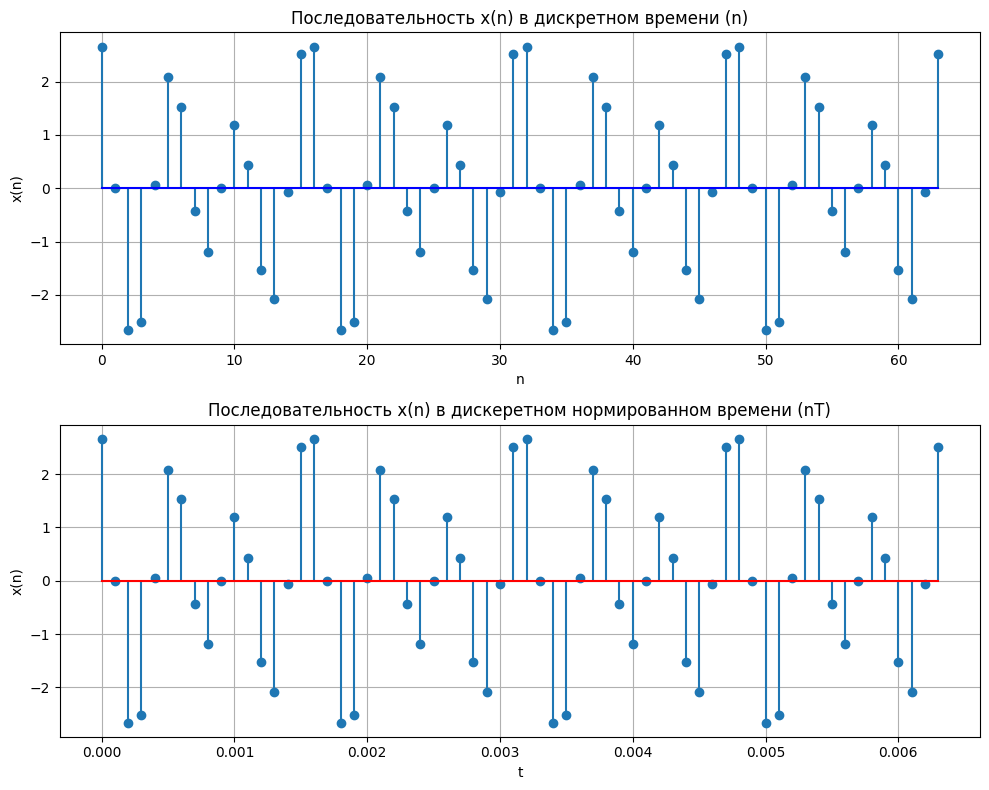

In [131]:
n_array = np.arange(N)
nT_array = n_array * T
x_n = A1 * np.cos(2 * np.pi * f1 * n_array * T + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * n_array * T + np.pi/8)

fig, axs = plt.subplots(2, 1, figsize=(10, 8))
axs[0].stem(n_array, x_n, basefmt="b-")
axs[0].set_title('Последовательность x(n) в дискретном времени (n)')
axs[0].set_xlabel('n')
axs[0].set_ylabel('x(n)')
axs[0].grid(True)

axs[1].stem(nT_array, x_n, basefmt="r-")
axs[1].set_title('Последовательность x(n) в дискеретном нормированном времени (nT)')
axs[1].set_xlabel('t')
axs[1].set_ylabel('x(n)')
axs[1].grid(True)
plt.tight_layout()
plt.show()

Исследуемый сигнал задан формулой:

$$
x(nT) = A_1 \cos(2\pi f_1 n T + \pi/4) + A_2 \cos(2\pi f_2 n T + \pi/8)
$$

где $ A_1, A_2 $ - амплитуды, $ f_1, f_2 $ - частоты гармоник, $ n $ - индекс дискретного отсчета, $ T $ - период дискретизации.

#### 2. ОДПФ от ДПФ последовательности x(n)

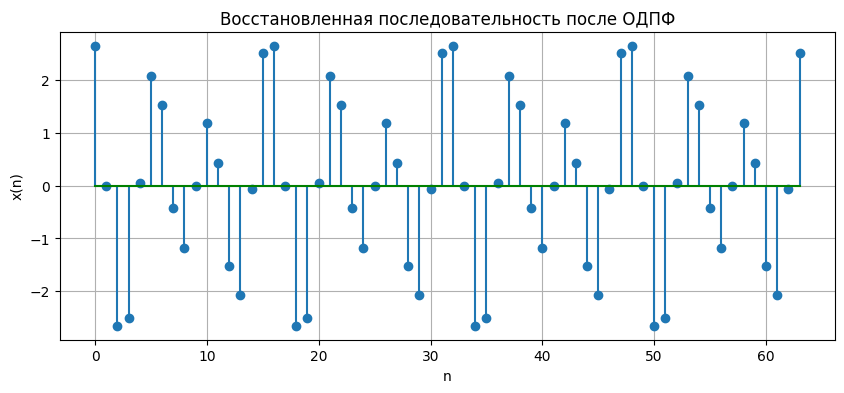

In [132]:
# прямое ДПФ
X_k = np.zeros(N, dtype=complex)
for k in range(N):
    sum_val = 0
    for n in range(N):
        sum_val += x_n[n] * np.exp(-1j * 2 * np.pi * k * n / N)
    X_k[k] = sum_val

# обратное ДПФ
x_idft = np.zeros(N, dtype=complex)
for n in range(N):
    sum_val = 0
    for k in range(N):
        sum_val += X_k[k] * np.exp(1j * 2 * np.pi * k * n / N)
    x_idft[n] = sum_val / N

x_idft = x_idft.real

plt.figure(figsize=(10, 4))
plt.stem(n_array, x_idft, basefmt="g-")
plt.title('Восстановленная последовательность после ОДПФ')
plt.xlabel('n')
plt.ylabel('x(n)')
plt.grid(True)
plt.show()

Прямое ДПФ вычисляет спектральные коэффициенты $ X(k) $ по формуле:

$$
X(k) = \sum_{n=0}^{N-1} x(n) e^{-j \frac{2\pi}{N} k n}, \quad k = 0, 1, \dots, N-1
$$

Обратное ДПФ (ОДПФ) восстанавливает исходный сигнал по его спектру:

$$
x(n) = \frac{1}{N} \sum_{k=0}^{N-1} X(k) e^{j \frac{2\pi}{N} k n}, \quad n = 0, 1, \dots, N-1
$$

#### 3. Амплитудный и фазовый спектры последовательности x(n)

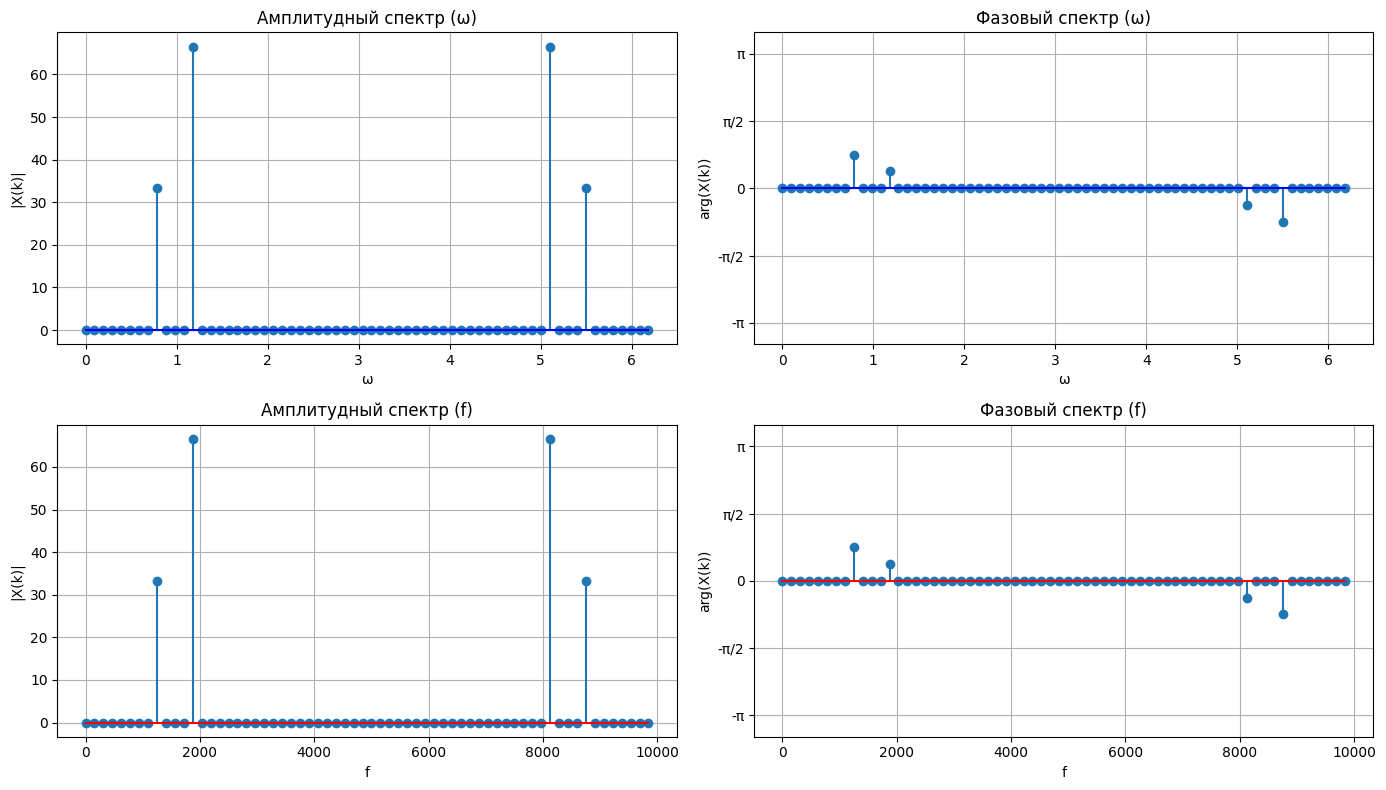

In [133]:
# модуль спектра
X_amp = np.abs(X_k)
# исходная фаза
X_phase = np.angle(X_k)

# если амплитуда меньше порогового значения (близка к нулю), фаза не определена (считаем ее нулевой)
threshold = 1e-4 * np.max(X_amp)

# убираем значения, где амплитуда близка к 0
X_phase_clean = np.where(X_amp > threshold, X_phase, 0)

# частотные оси
f_abs = np.arange(N) * fd / N
omega_norm_dft = 2 * np.pi * np.arange(N) / N

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
# амплитудные спектры
axs[0, 0].stem(omega_norm_dft, X_amp, basefmt="b-")
axs[0, 0].set_title('Амплитудный спектр (ω)')
axs[0, 0].set_xlabel('ω')
axs[0, 0].set_ylabel('|X(k)|')
axs[0, 0].grid(True)
axs[1, 0].stem(f_abs, X_amp, basefmt="r-")
axs[1, 0].set_title('Амплитудный спектр (f)')
axs[1, 0].set_xlabel('f')
axs[1, 0].set_ylabel('|X(k)|')
axs[1, 0].grid(True)
# фазовые спектры
axs[0, 1].stem(omega_norm_dft, X_phase_clean, basefmt="b-")
axs[0, 1].set_title('Фазовый спектр (ω)')
axs[0, 1].set_xlabel('ω')
axs[0, 1].set_ylabel('arg(X(k))')
axs[0, 1].set_ylim([-np.pi - 0.5, np.pi + 0.5])
axs[0, 1].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
axs[0, 1].set_yticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
axs[0, 1].grid(True)
axs[1, 1].stem(f_abs, X_phase_clean, basefmt="r-")
axs[1, 1].set_title('Фазовый спектр (f)')
axs[1, 1].set_xlabel('f')
axs[1, 1].set_ylabel('arg(X(k))')
axs[1, 1].set_ylim([-np.pi - 0.5, np.pi + 0.5])
axs[1, 1].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
axs[1, 1].set_yticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
axs[1, 1].grid(True)
plt.tight_layout()
plt.show()

a. Дискретное время $ t $ представляет собой последовательность моментов взятия отсчетов:

$$
t_n = nT, \quad n = 0, 1, \dots, N-1
$$

Нормированное дискретное время (индекс) получается путем деления реального времени на период дискретизации:

$$
\frac{t_n}{T} = n
$$

b. Дискретная нормированная частота $ \omega $ (в радианах/отсчет) и абсолютная частота $ f $ (в Гц) связаны через частоту дискретизации $ f_d = \frac{1}{T} $):

$$
\omega = 2\pi \frac{f}{f_d}
$$

Абсолютные частоты: $ f_k = k \frac{f_d}{N} $ (где $ k = 0, 1, \dots, N-1 $). Диапазон изменения от $ 0 $ до $ f_d $.

Нормированные частоты: $ \omega_k = k \frac{2\pi}{N} $. Диапазон изменения от $ 0 $ до $ 2\pi $.

c. Вид амплитудного и фазового спектров.

Исследуемая последовательность представляет собой сумму двух гармонических составляющих:

$$
x(n)=A_1\cos\left(2\pi f_1nT+\frac{\pi}{4}\right)
+A_2\cos\left(2\pi f_2nT+\frac{\pi}{8}\right),
$$

где амплитуды и частоты гармоник определяются выражениями:

$$
A_1=1.04,
\qquad
A_2=1.08,
$$

$$
f_1=\frac{f_d}{8},
\qquad
f_2=1.5f_1=\frac{3f_d}{16}.
$$

Нормированные частоты:

$$
\omega_1=2\pi\frac{f_1}{f_d}
=2\pi\frac{1}{8}
=\frac{\pi}{4},
$$

$$
\omega_2=2\pi\frac{f_2}{f_d}
=2\pi\frac{3}{16}
=\frac{3\pi}{8}.
$$

Следовательно, последовательность содержит две гармонические составляющие с нормированными частотами:

$$
\omega_1=\frac{\pi}{4},\qquad
\omega_2=\frac{3\pi}{8}.
$$

Для $ N=64 $ соответствующие номера спектральных отсчетов определяются как:

$$
k_1=\frac{Nf_1}{f_d}
=\frac{64}{8}=8,
$$

$$
k_2=\frac{Nf_2}{f_d}
=\frac{64\cdot3}{16}=12.
$$

Таким образом, амплитудный спектр содержит выраженные пики на частотах:

$$
k_1=8,\qquad k_2=12.
$$

Поскольку последовательность является вещественной, ее спектр обладает свойством симметрии:

$$
|X(k)|=|X(N-k)|.
$$

Поэтому дополнительные пики наблюдаются при:

$$
k_1'=64-8=56,
$$

$$
k_2'=64-12=52.
$$

Для прямого ДПФ без нормировки амплитуды спектральных пиков составляют:

$$
|X(8)|=|X(56)|=\frac{NA_1}{2}=32A_1,
$$

$$
|X(12)|=|X(52)|=\frac{NA_2}{2}=32A_2.
$$

Так как $ A_2=2A_1 $, второй гармонический пик в два раза выше первого:

$$
|X(12)|=2|X(8)|.
$$

Таким образом, амплитудный спектр является дискретным и содержит четыре основных пика, соответствующих двум гармоникам и их зеркальным отражениям, что видно на графиках.

Фазовый спектр определяется аргументом комплексных значений ДПФ:

$$
\varphi(k)=\arg X(k).
$$

Для первой гармоники начальная фаза составляет:

$$
\varphi_1=\frac{\pi}{4}.
$$

Для второй гармоники:

$$
\varphi_2=\frac{\pi}{8}.
$$

Следовательно, в фазовом спектре наблюдаются значения:

$$
\varphi(8)=\frac{\pi}{4},
$$

$$
\varphi(12)=\frac{\pi}{8}.
$$

Для зеркальных спектральных составляющих справедливо:

$$
X(N-k)=X^*(k),
$$

где $ X^*(k) $ - комплексно-сопряженное значение спектра.

Поэтому фазы зеркальных составляющих имеют противоположные знаки:

$$
\varphi(56)=-\frac{\pi}{4},
$$

$$
\varphi(52)=-\frac{\pi}{8}.
$$

В остальных спектральных точках амплитуда близка к нулю.

Фазовый спектр является дискретным и отражает начальные фазы гармонических составляющих исходной последовательности, что соответствует графикам.

#### 4. ДПФ конечной последовательности x(n) длины N



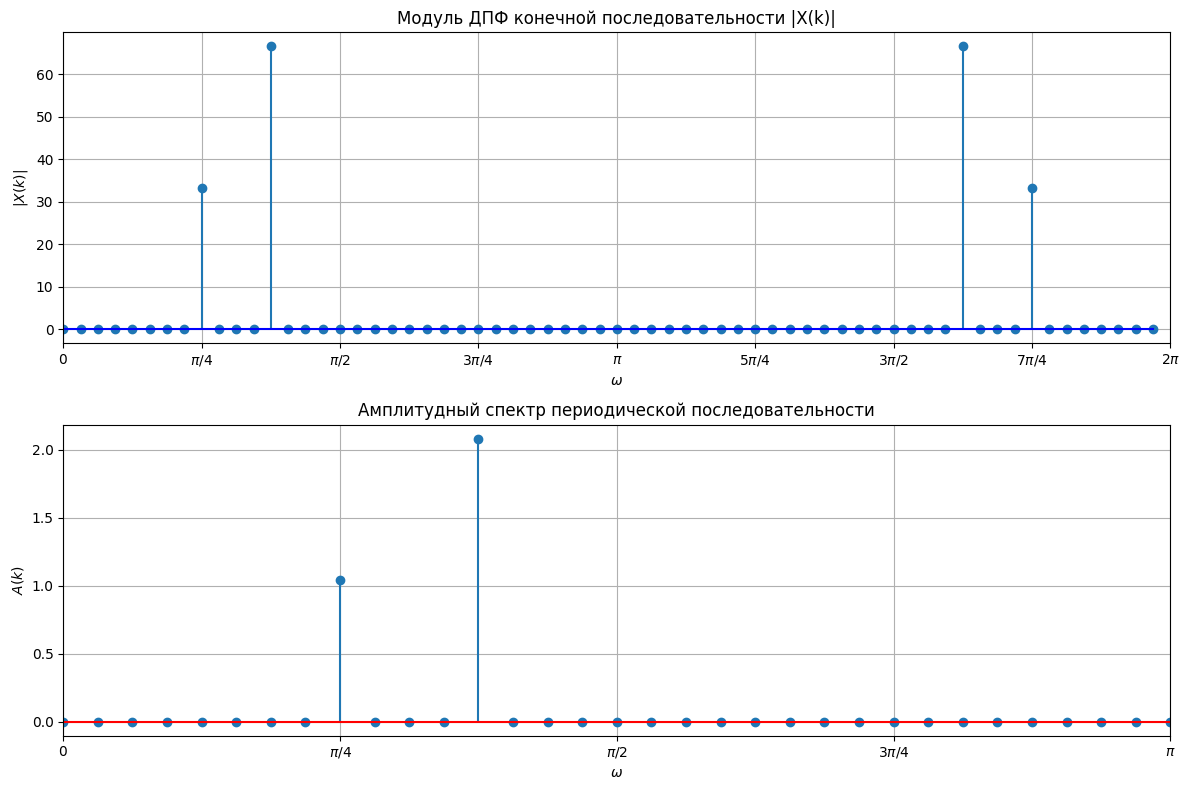

In [134]:
# модуль ДПФ конечной последовательности
X_mod = np.abs(X_k)

# дискретная нормированная частота
omega = 2 * np.pi * np.arange(N) / N

# амплитудный спектр периодической последовательности
A_spectrum = X_mod[:N // 2 + 1] / N

# удвоение амплитуд внутренних спектральных составляющих
A_spectrum[1:-1] *= 2

# частотная ось для одностороннего спектра
omega_one = omega[:N // 2 + 1]

fig, axs = plt.subplots(2, 1, figsize=(12, 8))
axs[0].stem(omega, X_mod, basefmt="b-")
axs[0].set_title('Модуль ДПФ конечной последовательности |X(k)|')
axs[0].set_xlabel(r'$\omega$')
axs[0].set_ylabel(r'$|X(k)|$')
axs[0].set_xlim(0, 2 * np.pi)
axs[0].set_xticks([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4, 2*np.pi],[r'$0$', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$', r'$5\pi/4$', r'$3\pi/2$', r'$7\pi/4$', r'$2\pi$'])
axs[0].grid(True)
axs[1].stem(omega_one, A_spectrum, basefmt="r-")
axs[1].set_title('Амплитудный спектр периодической последовательности')
axs[1].set_xlabel(r'$\omega$')
axs[1].set_ylabel(r'$A(k)$')
axs[1].set_xlim(0, np.pi)
axs[1].set_xticks([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi],[r'$0$', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
axs[1].grid(True)
plt.tight_layout()
plt.show()


Амплитудный спектр периодической последовательности получается из модуля ДПФ путем нормировки на длину последовательности $ N $.

Модуль ДПФ конечной последовательности и амплитудный спектр периодической последовательности имеют одинаковое расположение спектральных пиков. Различие между ними заключается в масштабе значений.

Для двустороннего спектра:

$$
A(k)=\frac{|X(k)|}{N}.
$$

Для одностороннего амплитудного спектра:

$$
A(k)=\frac{2|X(k)|}{N}
$$

для внутренних гармонических составляющих.

В результате нормировки спектральные пики приобретают значения, соответствующие амплитудам гармоник исходного сигнала.

#### 5. Восстановление периодического  аналогового сигнала x(t) по отсчётам ДПФ X(k) периодической последовательности x(n)


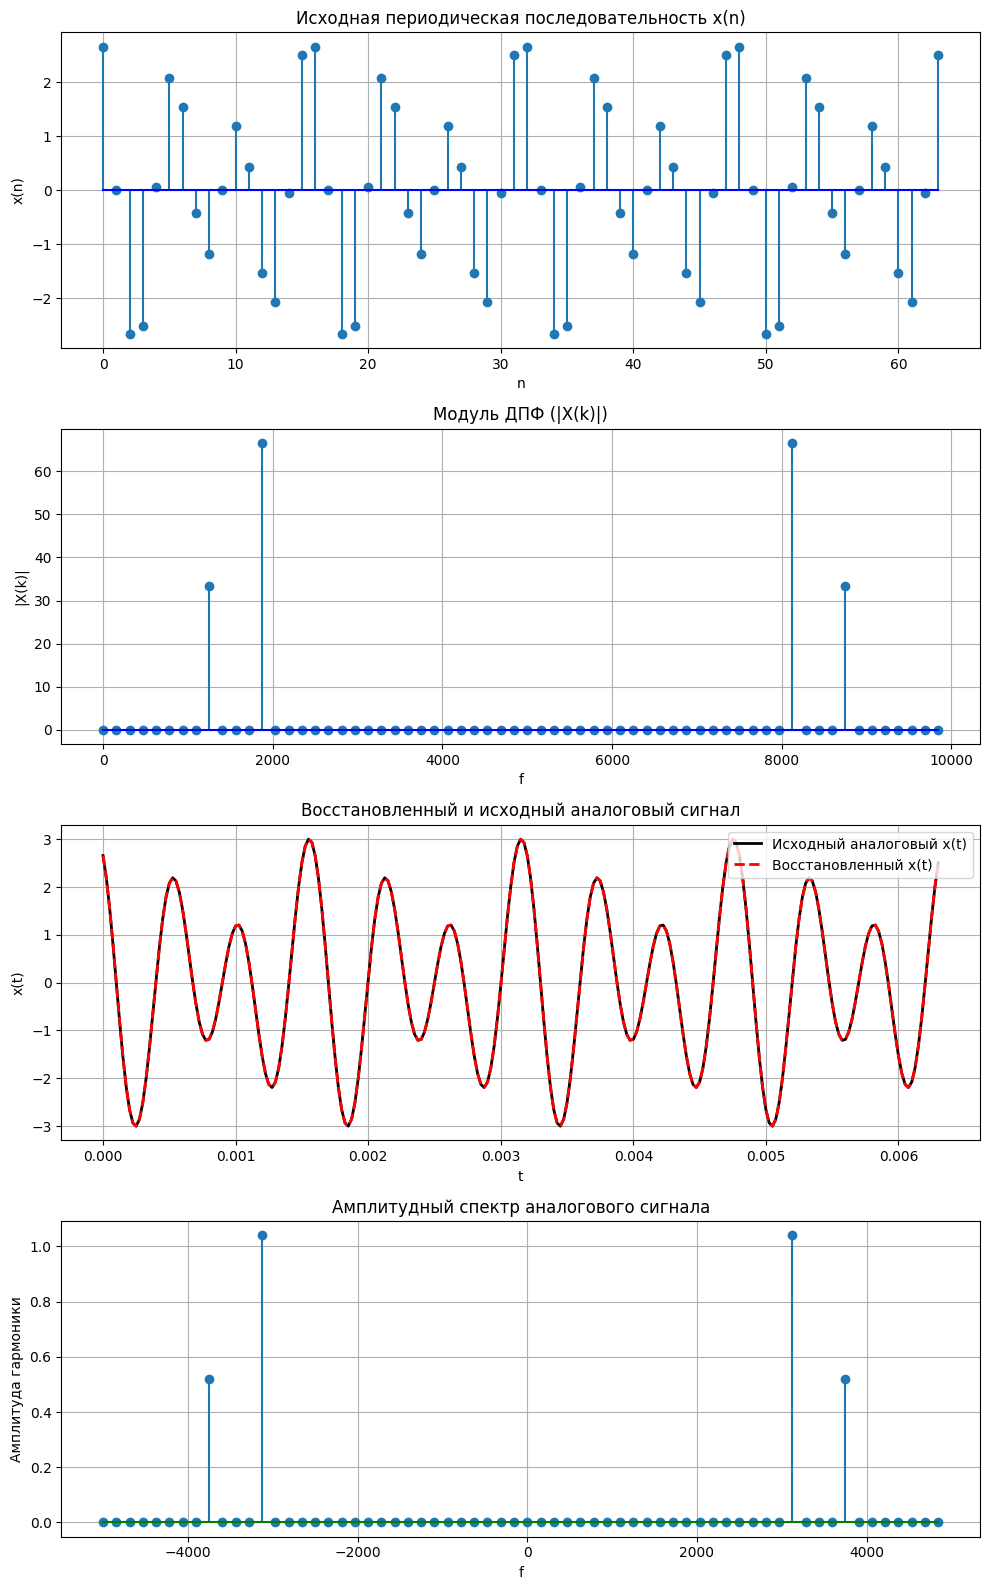

In [135]:
# массив X_a(k)
Xa = np.zeros(N, dtype=complex)
for k in range(N):
    # переводим индексы k из диапазона [-N/2, N/2-1] в индексы массива [0, N-1]
    k_shifted = k if k < N//2 else k - N
    if -N//2 <= k_shifted <= -1:
        Xa[k] = X_k[N + k_shifted]
    elif 0 <= k_shifted <= N//2 - 1:
        Xa[k] = X_k[k_shifted]

# интервал времени t
t_recon = np.arange(0, (N - 1)*T + 0.25*T, 0.25*T)
x_recon = np.zeros(len(t_recon))

# восстановление по формуле
for i, t_val in enumerate(t_recon):
    sum_val = 0
    for k_shifted in range(-N//2, N//2):
        k_idx = k_shifted % N
        sum_val += Xa[k_idx] * np.exp(1j * (2 * np.pi / (N * T)) * k_shifted * t_val)
    x_recon[i] = (sum_val / N).real

# исходный аналоговый сигнал для сравнения
x_analog_true = A1 * np.cos(2 * np.pi * f1 * t_recon + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * t_recon + np.pi/8)

# амплитудный спектр аналогового сигнала
Xa_amp = np.abs(Xa) / N
# частоты для сдвинутого спектра
f_shifted = np.arange(-N//2, N//2) * fd / N

fig, axs = plt.subplots(4, 1, figsize=(10, 16))
axs[0].stem(n_array, x_n, basefmt="b-")
axs[0].set_title('Исходная периодическая последовательность x(n)')
axs[0].set_xlabel('n')
axs[0].set_ylabel('x(n)')
axs[0].grid(True)
axs[1].stem(f_abs, X_amp, basefmt="b-")
axs[1].set_title('Модуль ДПФ (|X(k)|)')
axs[1].set_xlabel('f')
axs[1].set_ylabel('|X(k)|')
axs[1].grid(True)
axs[2].plot(t_recon, x_analog_true, 'k-', linewidth=2, label='Исходный аналоговый x(t)')
axs[2].plot(t_recon, x_recon, 'r--', linewidth=2, label='Восстановленный x(t)')
axs[2].set_title('Восстановленный и исходный аналоговый сигнал')
axs[2].set_xlabel('t')
axs[2].set_ylabel('x(t)')
axs[2].legend()
axs[2].grid(True)
axs[3].stem(f_shifted, Xa_amp, basefmt="g-")
axs[3].set_title('Амплитудный спектр аналогового сигнала')
axs[3].set_xlabel('f')
axs[3].set_ylabel('Амплитуда гармоники')
axs[3].grid(True)
plt.tight_layout()
plt.show()

#### 6. Связь модуля ДПФ последовательности со спектром аналогового сигнала и
сравнения восстановленного и исходного сигналов

а. Связь между ДПФ последовательности и спектром восстановленного аналогового сигнала.

Модуль ДПФ $ |X(k)| $ показывает суммарную амплитуду гармоники в дискретной последовательности. Чтобы получить истинную амплитуду гармоники аналогового сигнала (коэффициент ряда Фурье), необходимо нормировать модуль ДПФ на количество отсчетов в периоде $ N $. Это можно заметить на графиках: пик модуля ДПФ составляет примерно $ 66 $. При делении на $ N=64 $ получается значение $ 66/64 \approx 1.03 $, что совпадает с высотой пика на графике амплитудного спектра аналогового сигнала. Для второй гармоники: $ 33/64 \approx 0.52 $.

Спектр аналогового сигнала является двусторонним. Так как исходный сигнал $ x(t) $ вещественный, его спектр симметричен относительно нулевой частоты. На графике амплитудного спектра видно пики на положительных и отрицательных частотах. При этом амплитуда каждой из пары пиков равна $ A/2 $, где $ A $ - амплитуда косинусоиды во временной области.
    
Модуль ДПФ отображается в диапазоне от $ 0 $ до $ f_d $ (частоты дискретизации). Спектр аналогового сигнала отображается в диапазоне от $ -f_d/2 $ до $ f_d/2 $. Это достигается за счет сдвига и центрирования частот, что физически отражает непрерывный характер аналогового сигнала.

b. Результат визуального сравнения восстановленного и исходного сигналов

На графике «Восстановленный и исходный аналоговый сигнал» видно, что графики исходного сигнала $ x(t) $ и восстановленного сигнала полностью совпадают.

Обратное дискретное преобразование Фурье точно восстанавливает исходные дискретные отсчеты $ x(n) $.


#### 7. Равенство Парсеваля

In [136]:
# левая часть
E_time = np.sum(np.abs(x_n)**2)

# правая часть
E_freq = (1/N) * np.sum(np.abs(X_k)**2)

print(f"Энергия во временной области: {E_time:.4f}")
print(f"Энергия в частотной области: {E_freq:.4f}")
print(f"Разница (абсолютная погрешность): {abs(E_time - E_freq):.10f}")

Энергия во временной области: 173.0560
Энергия в частотной области: 173.0560
Разница (абсолютная погрешность): 0.0000000000


Равенство Парсеваля (для дискретного преобразования Фурье) утверждает, что полная энергия сигнала во временной области равна полной энергии его спектра в частотной области. Математически это записывается следующим образом:

$$
    \sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X(k)|^2
$$

где: $ x(n) $ - отсчеты дискретного сигнала во временной области; $ X(k) $ - коэффициенты ДПФ; $ N $ - количество отсчетов.

Полученная абсолютная погрешность равна нулю (с точностью до машинного представления чисел с плавающей точкой). Это означает, что равенство Парсеваля выполняется численно.

Смысл теоремы заключается в том, что преобразование Фурье не создает и не уничтожает энергию сигнала. Сколько энергии было в исходном сигнале во времени, столько же ее будет содержаться в его частотных составляющих.

## Выводы

В процессе выполнения лабораторной работы были изучены методы математического описания линейных дискретных систем, а также основы спектрального анализа периодических последовательностей и сигналов конечной длины с применением дискретного преобразования Фурье (ДПФ).

В первой части работы была исследована линейная дискретная система. Была рассчитана ее импульсная характеристика, которая теоретически является бесконечной, но на практике была ограничена. Сравнение реакции системы, полученной через линейную свертку и через разностное уравнение, показало их полное совпадение на начальном интервале. Незначительные расхождения на последующих отсчетах объясняются искусственным усечением импульсной характеристики при расчете свертки. Анализ карты нулей и полюсов подтвердил, что система является устойчивой, так как все полюсы передаточной функции лежат внутри единичной окружности. Построение АЧХ и ФЧХ в нормированной и абсолютной шкалах частот позволило наглядно оценить избирательные свойства фильтра: наличие комплексно-сопряженных полюсов вблизи единичной окружности обусловило появление выраженного резонансного пика на определенных частотах, а также было проанализировано преимущественное подавление низкочастотных составляющих.

Во второй части работы с помощью ДПФ был проведен детальный спектральный анализ дискретной последовательности, состоящей из двух гармоник. Прямое и обратное ДПФ (ОДПФ) подтвердили свойство обратимости - исходный сигнал был восстановлен без потерь. Анализ амплитудного и фазового спектров показал их симметричность (для вещественного сигнала) и позволил точно определить частоты и начальные фазы гармонических составляющих. Кроме того, по коэффициентам ДПФ был успешно восстановлен непрерывный аналоговый сигнал $ x(t) $. Визуальное сравнение показало его идеальное совпадение с исходным аналоговым сигналом. Завершающим этапом стала проверка равенства Парсеваля, которая численно доказала, что полная энергия сигнала во временной области в точности равна энергии его спектральных составляющих в частотной области.